In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.visualisation.quinex_visualisation import QuinexVisualisation

In [2]:
visualisation = QuinexVisualisation()

### **Import Results**

#### **LCOE**

In [3]:
cost_lcoe = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoe2024.xlsx")
cost_lcoe = cost_lcoe[cost_lcoe["entity_base_mapping"].isin(['PV'])]

In [4]:
cost_lcoe = visualisation.convert_spatial(cost_lcoe, spatial_col="spatial_scope")
print(cost_lcoe["entity_base_mapping"].value_counts())

entity_base_mapping
PV    713
Name: count, dtype: int64


In [5]:
cost_lcoe = cost_lcoe[cost_lcoe["value_converted"] < 0.51]
len(cost_lcoe)

616

#### **Solar Radiation**

In [ ]:
import rasterio
import pandas as pd

# GeoTIFF öffnen
src = rasterio.open("../data/visualisation_files/ghi/GHI.tif")
coords = zip(
    cost_lcoe["longitude"],
    cost_lcoe["latitude"]
)

cost_lcoe["solar_radiation"] = [
    val[0] for val in src.sample(coords)
]

In [ ]:
def is_country_only(row):
    text = row["spatial_scope"]["text"].strip().lower()
    country = row["spatial_scope"]["country"].strip().lower()

    return (
        text == country
        or text == f"in {country}"
    )

mask = cost_lcoe.apply(is_country_only, axis=1)

cost_lcoe_solar = cost_lcoe[~mask]

### **Visualize Results**

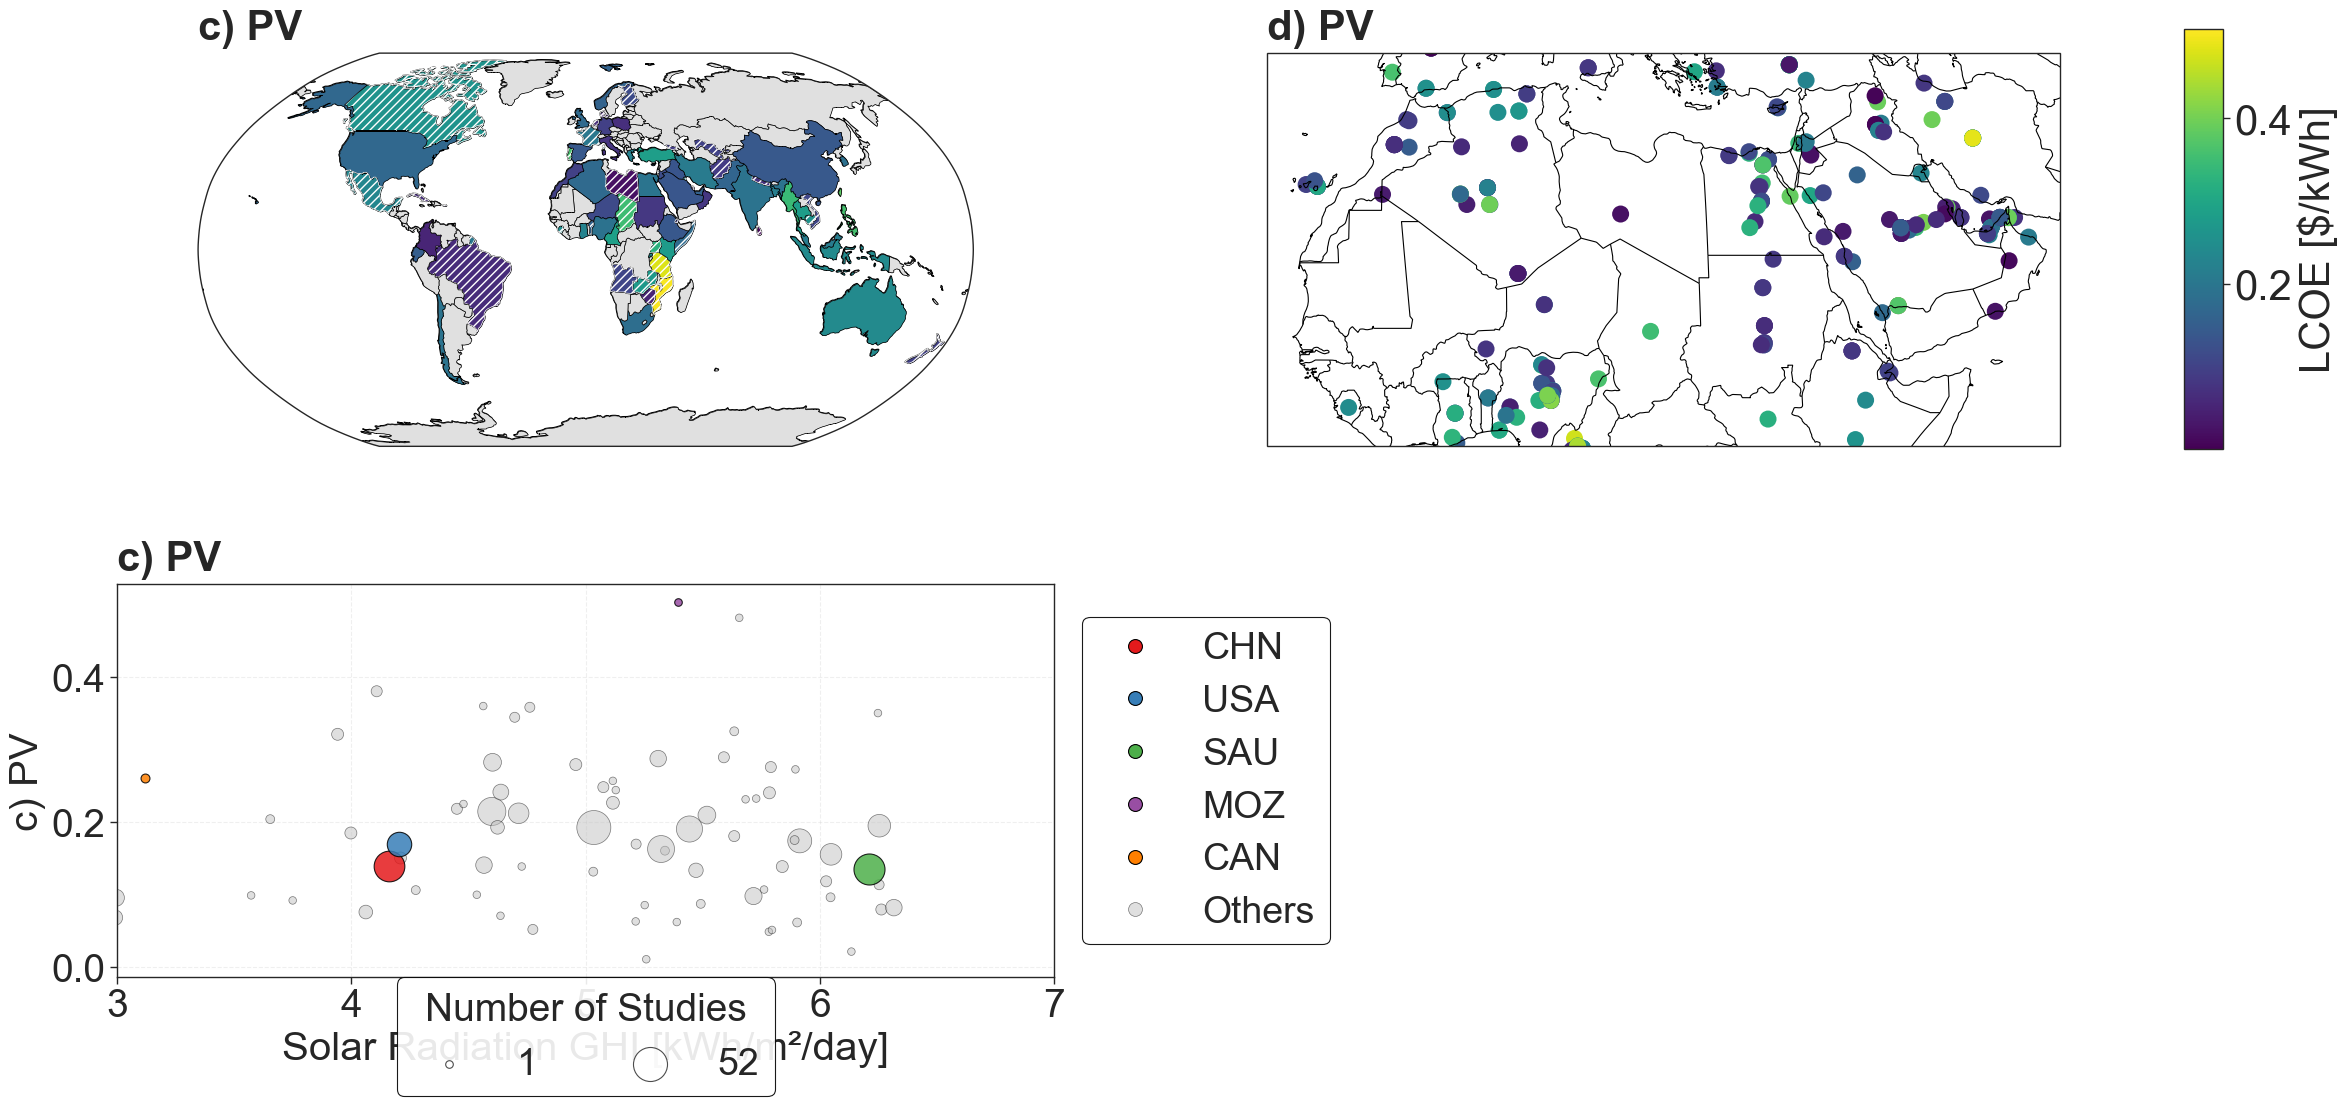

In [10]:
datasets = [
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'c) PV',
    'plot_mode': 'choropleth',
    'min_datapoints': 3,
    },
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'd) PV',
    'plot_mode': 'points',
    'spatial_extent': [-20, 60, 5, 40],
    },
    {
    'df': cost_lcoe,
    'value_column': 'value_converted',
    'title': 'c) PV',
    'plot_mode': 'size',
    'ghi_data_path': "../data/visualisation_files/ghi/country_GHI_mean.xlsx",
    'highlight_countries': ['CHN', 'USA', 'SAU', 'MOZ', 'CAN'],
    'x_range': [3,7],
    #'min_datapoints': 5,
    #'show_regression': True,
    },
]

fig, data_tables = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="LCOE [$/kWh]",
    figsize=(26, 12),
    jitter_strength=0,
    default_point_size=150,
    font_size=30,
)

#fig.savefig("../data/figures/results/spatial/lcoe_pv_new2.pdf", bbox_inches='tight')